<h1> Neural Network Fundamentals </h1>
<h2> (Implementation from scratch) </h2>

Implementing Neural Network Fundamentals with NumPy
- Perceptron and Artificial Neuron
- Forward Propagation
- Activation and Loss Functions
- Gradient Descent
- Backpropagation from Scratch

#### The Perceptron Model

A Perceptron computes a weighted sum of its inputs:

$z = \mathbf{w}^T \mathbf{x} + b$

It then applies a step activation function:

$\hat{y} =
\begin{cases}
1 & z \geq 0 \\
0 & z < 0
\end{cases}$

#### Learning Rule

The weights and bias are updated when a prediction is incorrect:

$\mathbf{w} \leftarrow \mathbf{w} + \eta(y-\hat{y})\mathbf{x}$

$b \leftarrow b + \eta(y-\hat{y})$

where:
- $\eta$ is the learning rate.
- $y$ is the target label.
- $\hat{y}$ is the predicted label.

In [4]:
import numpy as np
import matplotlib.pyplot as plt

from src.nn import Perceptron

<h3> Step 1: Data Preparation (AND Function)

To begin, we use the simple AND problem. This problem allows us to examine how weights are learned, without the complexity of a dataset.

In [2]:
# AND gate dataset
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=float)

y = np.array([0, 0, 0, 1], dtype=int)

print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nInputs:")
print(X)

print("\nTargets:")
print(y)

Input shape: (4, 2)
Target shape: (4,)

Inputs:
[[0. 0.]
 [0. 1.]
 [1. 0.]
 [1. 1.]]

Targets:
[0 0 0 1]


In other words, we have four samples, each with two features, and their target output is either zero or one.

<h3> Step 2: Implementing a Perceptron from Scratch

<h4> A perceptron is a single artificial neuron.

At this stage, we do not use any pre-built models. We write the weights, biases, prediction function, and learning rule ourselves.

Important note: For this educational example, we have set the initial bias value to -0.5 so that we can observe the learning process for the AND operation in a simple and reproducible way. This is an initial choice for experimental purposes, not a value that the model must always start with.

<h3> Step 3: Training and Evaluation

In [3]:
model = Perceptron(learning_rate=0.1, epochs=20)

model.fit(X, y)

predictions = model.predict(X)

print("Learned weights:", model.weights)
print("Learned bias:", model.bias)

print("\nPredictions:", predictions)
print("Targets:     ", y)

print("\nErrors per epoch:", model.errors_)
print("Training accuracy:", np.mean(predictions == y))

Learned weights: [0.2 0.2]
Learned bias: -0.30000000000000004

Predictions: [0 0 0 1]
Targets:      [0 0 0 1]

Errors per epoch: [1, 1, 0]
Training accuracy: 1.0


What did we learn?
- Weights: Determine the extent to which each input influences a neuron's decision.
- Bias: Shifts the decision threshold.
- Activation: Converts the calculated value into a class of 0 or 1.
- Learning rule: Adjusts the weights and bias in the event of an incorrect prediction.
- Training accuracy: In this example, it reached 100% because the AND operation is a linearly separable problem.

<h3> Step 4: Plotting the Decision Boundary

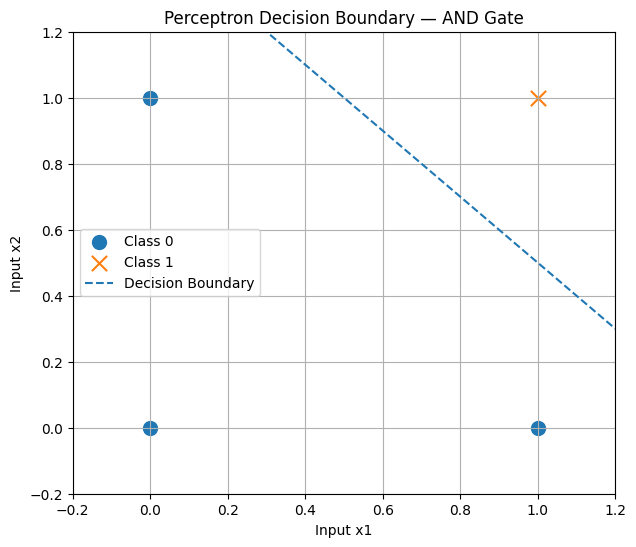

In [5]:
# Separate the two classes
class_0 = X[y == 0]
class_1 = X[y == 1]

plt.figure(figsize=(7, 6))

plt.scatter(
    class_0[:, 0], class_0[:, 1],
    label="Class 0", marker="o", s=100
)

plt.scatter(
    class_1[:, 0], class_1[:, 1],
    label="Class 1", marker="x", s=120
)

# Decision boundary:
# w1*x1 + w2*x2 + b = 0
x1_line = np.linspace(-0.2, 1.2, 100)
x2_line = -(
    model.weights[0] * x1_line + model.bias
) / model.weights[1]

plt.plot(
    x1_line, x2_line,
    linestyle="--",
    label="Decision Boundary"
)

plt.xlabel("Input x1")
plt.ylabel("Input x2")
plt.title("Perceptron Decision Boundary — AND Gate")
plt.xlim(-0.2, 1.2)
plt.ylim(-0.2, 1.2)
plt.grid(True)
plt.legend()
plt.show()

<h3> Step 5: Definition of the XOR dataset

<h4> The XOR Experiment and the Perceptron Limitation

In the previous experiment, we saw that a Perceptron can solve the AND problem with 100% accuracy. Now, we want to examine whether this same model can also learn the XOR problem.

In [6]:
# XOR dataset
X_xor = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=float)

y_xor = np.array([0, 1, 1, 0], dtype=int)

print("Inputs:")
print(X_xor)

print("\nTargets:")
print(y_xor)

Inputs:
[[0. 0.]
 [0. 1.]
 [1. 0.]
 [1. 1.]]

Targets:
[0 1 1 0]


<h3> Step 6: Training the Perceptron

We do not modify the previous class. We simply train a new model on the XOR data.

In [7]:
xor_model = Perceptron(
    learning_rate=0.1,
    epochs=20
)

xor_model.fit(X_xor, y_xor)

xor_predictions = xor_model.predict(X_xor)

print("Learned weights:", xor_model.weights)
print("Learned bias:", xor_model.bias)

print("\nPredictions:", xor_predictions)
print("Targets:     ", y_xor)

print("\nErrors per epoch:", xor_model.errors_)

accuracy = np.mean(xor_predictions == y_xor)
print("Training accuracy:", accuracy)

Learned weights: [-0.1  0. ]
Learned bias: 0.09999999999999998

Predictions: [1 1 0 0]
Targets:      [0 1 1 0]

Errors per epoch: [2, 3, 3, 2, 3, 2, 2, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
Training accuracy: 0.5


#### Why does the model fail?
AND: Linearly separable problem

The classes can be separated by a straight line; therefore, a single Perceptron is sufficient.

XOR: Non-linearly separable problem

Samples of class 0 are located in two diagonally opposite corners, while samples of class 1 are in the other two corners. No straight line can completely separate these two classes.

This limitation does not stem from insufficient training or an inadequate number of epochs; a perceptron with a linear decision boundary is fundamentally incapable of fully solving the XOR problem.

<h3> Step 7: XOR Plot and Decision Boundary

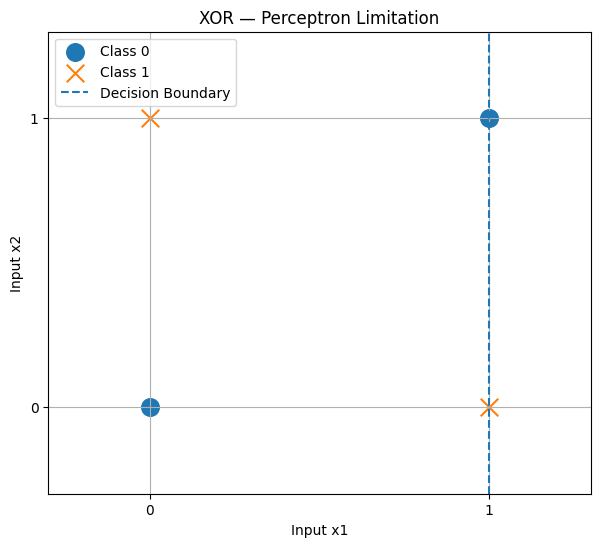

In [8]:
class_0 = X_xor[y_xor == 0]
class_1 = X_xor[y_xor == 1]

plt.figure(figsize=(7, 6))

plt.scatter(
    class_0[:, 0], class_0[:, 1],
    s=160, marker="o", label="Class 0"
)

plt.scatter(
    class_1[:, 0], class_1[:, 1],
    s=160, marker="x", label="Class 1"
)

# Plot the learned linear decision boundary
w1, w2 = xor_model.weights
bias = xor_model.bias

if abs(w2) > 1e-12:
    x1_line = np.linspace(-0.3, 1.3, 100)
    x2_line = -(w1 * x1_line + bias) / w2
    plt.plot(x1_line, x2_line, "--", label="Decision Boundary")
elif abs(w1) > 1e-12:
    boundary_x = -bias / w1
    plt.axvline(
        boundary_x,
        linestyle="--",
        label="Decision Boundary"
    )

plt.xlabel("Input x1")
plt.ylabel("Input x2")
plt.title("XOR — Perceptron Limitation")
plt.xticks([0, 1])
plt.yticks([0, 1])
plt.xlim(-0.3, 1.3)
plt.ylim(-0.3, 1.3)
plt.grid(True)
plt.legend()
plt.show()

In the diagram, we can see that the samples of class zero are located in two diagonally opposite corners, while the samples of class one are in the other two corners; consequently, a straight line cannot separate these two classes.

#### Conclusion:

- AND: A perceptron with a linear decision boundary can solve the problem.
- XOR: A simple perceptron cannot fully solve the problem; doing so requires a network with a hidden layer and a non-linear activation function.

<h3> Step 8: 